# LLM Profiling Framework MVP — Level 1

## Mục tiêu

Notebook này chuẩn hóa benchmark LLM để kết quả **ổn định hơn, dễ tái lập hơn và dễ diễn giải hơn**.

Các cải tiến chính:
- Nạp tokenizer/model **một lần**, tái sử dụng cho tất cả cấu hình.
- Warm-up theo từng cấu hình; số lần đo mặc định tăng lên 10.
- Báo cáo median, mean, standard deviation, min/max và p90.
- Ghi rõ định nghĩa các metric và những phần **không** nằm trong thời gian đo.
- Tự động lưu dữ liệu thô, bảng tổng hợp, cấu hình và thông tin môi trường ra CSV/JSON.
- Biểu đồ cho baseline và hai thí nghiệm: prompt length, generation length.

> Notebook vẫn là benchmark ở mức model. RSS là bộ nhớ của toàn bộ tiến trình Python; số đo bộ nhớ backend chỉ được ghi khi PyTorch cung cấp API tương ứng. Notebook không tự suy ra GPU memory bandwidth, L2 cache hay nguyên nhân bottleneck từ latency.


## 1. Chuẩn bị môi trường

Mở notebook bằng kernel của virtual environment đã cài các thư viện trong dự án. Từ thư mục dự án, có thể cài package bằng:

```bash
pip install -e .
```

Các thư viện cần có: `torch`, `transformers`, `pandas`, `matplotlib`, `psutil`, `nbformat` (chỉ cần `nbformat` nếu muốn thao tác notebook bằng Python; không cần cho quá trình benchmark). Lần đầu tải model từ Hugging Face có thể cần Internet.


In [6]:
from pathlib import Path
import os
import sys
import json
import gc
import time
import platform
import statistics
from datetime import datetime, timezone

import pandas as pd
import matplotlib.pyplot as plt
import psutil
import torch
import transformers
from transformers import AutoTokenizer, AutoModelForCausalLM

print("Python:", sys.version.split()[0])
print("Platform:", platform.platform())
print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)


Python: 3.12.11
Platform: macOS-26.6.2-arm64-arm-64bit
PyTorch: 2.14.1
Transformers: 5.19.0


## 2. Cấu hình benchmark

Để so sánh công bằng, hãy chỉ thay đổi biến đang được nghiên cứu và giữ nguyên các biến khác. Có thể giảm `REPEATS` nếu máy chạy chậm, nhưng nên dùng ít nhất 10 lượt đo cho kết quả báo cáo cuối cùng.

In [7]:
# Cấu hình chung
MODEL = "sshleifer/tiny-gpt2"
DEVICE_REQUESTED = "auto"  # "auto", "mps", "cuda", hoặc "cpu"

PROMPT_TOKENS = 64
NEW_TOKENS = 32
REPEATS = 10
WARMUP = 2
SEED = 1234

OUTPUT_DIR = Path("results/notebook_level1")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

def choose_device(requested: str) -> str:
    if requested == "auto":
        if hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
            return "mps"
        if torch.cuda.is_available():
            return "cuda"
        return "cpu"
    if requested == "mps" and not (
        hasattr(torch.backends, "mps") and torch.backends.mps.is_available()
    ):
        raise RuntimeError("Đã yêu cầu MPS nhưng backend MPS không khả dụng.")
    if requested == "cuda" and not torch.cuda.is_available():
        raise RuntimeError("Đã yêu cầu CUDA nhưng CUDA không khả dụng.")
    if requested not in {"mps", "cuda", "cpu"}:
        raise ValueError("DEVICE_REQUESTED phải là auto, mps, cuda hoặc cpu.")
    return requested

DEVICE = choose_device(DEVICE_REQUESTED)
print("Selected device:", DEVICE)
print("MPS available:", bool(getattr(torch.backends, "mps", None) and torch.backends.mps.is_available()))
print("CUDA available:", torch.cuda.is_available())
print("Repeats:", REPEATS, "| Warm-up per configuration:", WARMUP)


Selected device: mps
MPS available: True
CUDA available: False
Repeats: 10 | Warm-up per configuration: 2


## 3. Nạp model một lần và định nghĩa phép đo

Tokenizer và model được nạp một lần rồi dùng lại xuyên suốt notebook. Tokenization được thực hiện **ngoài vùng thời gian inference**. Mỗi lượt đo gồm:
- **Prefill latency:** thời gian forward pass xử lý prompt và tạo KV cache.
- **Decode latency:** tổng thời gian các forward pass decode từng token tiếp theo, sử dụng KV cache.
- Token đầu tiên được chọn từ logits của Prefill, nên không nằm trong các bước decode được tính thời gian.
- **End-to-end model time:** Prefill + các bước decode đã đo; không gồm tải model, tokenization, lưu file hoặc vẽ biểu đồ.

Lưu ý: đây là phép đo wall-clock ở mức model, không phải phép đo kernel thuần. Việc đồng bộ thiết bị trước/sau vùng đo giúp tránh đọc thời gian quá sớm trên backend bất đồng bộ.


In [8]:
def sync_device(device: str) -> None:
    if device == "mps":
        torch.mps.synchronize()
    elif device == "cuda":
        torch.cuda.synchronize()

def make_prompt_ids(tokenizer, desired_tokens: int) -> torch.Tensor:
    # Trả về đúng số token đầu vào, tránh decode rồi tokenize lại gây lệch độ dài.
    seed_text = (
        "Profiling measures the performance of language model inference. "
        "The experiment records latency, throughput, and memory usage. "
    ) * max(8, desired_tokens // 8 + 4)
    ids = tokenizer(seed_text, add_special_tokens=False, return_tensors="pt").input_ids
    ids = ids[:, :max(1, desired_tokens)].clone()
    if ids.shape[1] < desired_tokens:
        raise ValueError(
            f"Không tạo đủ prompt token: cần {desired_tokens}, có {ids.shape[1]}."
        )
    return ids

def memory_snapshot(device: str) -> dict:
    process = psutil.Process(os.getpid())
    rss_mb = process.memory_info().rss / (1024 ** 2)
    allocated_mb = None
    reserved_or_driver_mb = None

    if device == "mps":
        try:
            allocated_mb = torch.mps.current_allocated_memory() / (1024 ** 2)
            driver_fn = getattr(torch.mps, "driver_allocated_memory", None)
            if driver_fn is not None:
                reserved_or_driver_mb = driver_fn() / (1024 ** 2)
        except Exception:
            pass
    elif device == "cuda":
        allocated_mb = torch.cuda.memory_allocated() / (1024 ** 2)
        reserved_or_driver_mb = torch.cuda.memory_reserved() / (1024 ** 2)

    return {
        "process_rss_mb": round(rss_mb, 3),
        "torch_allocated_mb": round(allocated_mb, 3) if allocated_mb is not None else None,
        "torch_reserved_or_driver_mb": round(reserved_or_driver_mb, 3)
            if reserved_or_driver_mb is not None else None,
    }

def run_once(model, device: str, prompt_ids_cpu: torch.Tensor, max_new_tokens: int) -> dict:
    # Chuyển tensor sang thiết bị trước khi bắt đầu bấm giờ.
    input_ids = prompt_ids_cpu.to(device)
    attention_mask = torch.ones_like(input_ids)

    # Prefill: xử lý toàn bộ prompt.
    sync_device(device)
    t0 = time.perf_counter()
    with torch.inference_mode():
        prefill_out = model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            use_cache=True,
        )
    sync_device(device)
    prefill_s = time.perf_counter() - t0

    past_key_values = prefill_out.past_key_values
    next_token = prefill_out.logits[:, -1, :].argmax(dim=-1, keepdim=True)
    del prefill_out

    # Decode: các bước sau token đầu tiên, mỗi bước đưa vào một token mới.
    decode_step_times = []
    current_mask = attention_mask
    with torch.inference_mode():
        for _ in range(max(0, max_new_tokens - 1)):
            current_mask = torch.cat(
                [
                    current_mask,
                    torch.ones(
                        (current_mask.shape[0], 1),
                        dtype=current_mask.dtype,
                        device=device,
                    ),
                ],
                dim=1,
            )
            sync_device(device)
            step_t0 = time.perf_counter()
            out = model(
                input_ids=next_token,
                attention_mask=current_mask,
                past_key_values=past_key_values,
                use_cache=True,
            )
            sync_device(device)
            decode_step_times.append(time.perf_counter() - step_t0)
            past_key_values = out.past_key_values
            next_token = out.logits[:, -1, :].argmax(dim=-1, keepdim=True)
            del out

    decode_s = float(sum(decode_step_times))
    total_s = float(prefill_s + decode_s)
    decode_calls = len(decode_step_times)

    # Snapshot trước khi các biến cục bộ chứa KV cache được giải phóng.
    memory = memory_snapshot(device)

    return {
        "prefill_latency_s": float(prefill_s),
        "decode_latency_s": decode_s,
        "decode_step_latency_mean_s": (
            float(statistics.mean(decode_step_times)) if decode_step_times else 0.0
        ),
        "decode_step_latency_p50_s": (
            float(statistics.median(decode_step_times)) if decode_step_times else 0.0
        ),
        "end_to_end_model_time_s": total_s,
        "generated_tokens_requested": int(max_new_tokens),
        "decode_steps_timed": int(decode_calls),
        # Throughput chỉ tính các bước decode được bấm giờ; token đầu tiên đến từ Prefill.
        "decode_steps_per_s": (decode_calls / decode_s) if decode_s > 0 else 0.0,
        # Throughput xấp xỉ của toàn bộ số token yêu cầu trên Prefill + timed Decode.
        "end_to_end_tokens_per_s": (
            max_new_tokens / total_s if total_s > 0 else 0.0
        ),
        "prompt_tokens_actual": int(input_ids.shape[-1]),
        **memory,
    }


In [9]:

# Khởi tạo model và tokenizer
torch.manual_seed(SEED)

print(f"Loading tokenizer: {MODEL}")
tokenizer = AutoTokenizer.from_pretrained(MODEL)

print(f"Loading model: {MODEL}")
model = AutoModelForCausalLM.from_pretrained(MODEL)
model = model.to(DEVICE)
model.eval()

# Ghi nhận mức sử dụng bộ nhớ sau khi tải model
loaded_memory = memory_snapshot(DEVICE) if "memory_snapshot" in globals() else {
    "process_rss_mb": psutil.Process(os.getpid()).memory_info().rss / (1024 ** 2)
}

print("Tokenizer loaded:", tokenizer is not None)
print("Model loaded:", model is not None)
print("Device:", DEVICE)
print("Memory after loading:", loaded_memory)


Loading tokenizer: sshleifer/tiny-gpt2
Loading model: sshleifer/tiny-gpt2


Loading weights:   0%|          | 0/29 [00:00<?, ?it/s]

[transformers] GPT2LMHeadModel LOAD REPORT from: sshleifer/tiny-gpt2
Key                                   | Status     |  | 
--------------------------------------+------------+--+-
transformer.h.{0, 1}.attn.masked_bias | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Tokenizer loaded: True
Model loaded: True
Device: mps
Memory after loading: {'process_rss_mb': 211.781, 'torch_allocated_mb': 0.398, 'torch_reserved_or_driver_mb': 8.391}


## 4. Hàm chạy một cấu hình và thống kê kết quả

Mỗi cấu hình có warm-up riêng để làm nóng đường thực thi tương ứng. Warm-up không được đưa vào thống kê. Dữ liệu mỗi lượt được lưu lại, sau đó tính thống kê phân bố để không chỉ dựa vào một con số đơn lẻ.


In [10]:
def run_configuration(
    prompt_tokens: int,
    max_new_tokens: int,
    repeats: int = REPEATS,
    warmup: int = WARMUP,
    experiment: str = "custom",
) -> list[dict]:
    prompt_ids_cpu = make_prompt_ids(tokenizer, prompt_tokens)

    for warmup_index in range(warmup):
        _ = run_once(model, DEVICE, prompt_ids_cpu, max_new_tokens)
        print(
            f"  warm-up {warmup_index + 1}/{warmup} "
            f"(prompt={prompt_tokens}, new={max_new_tokens})"
        )
    sync_device(DEVICE)

    rows = []
    for run_index in range(1, repeats + 1):
        gc.collect()
        row = run_once(model, DEVICE, prompt_ids_cpu, max_new_tokens)
        row.update({
            "timestamp_utc": datetime.now(timezone.utc).isoformat(),
            "experiment": experiment,
            "run_index": run_index,
            "model": MODEL,
            "device": DEVICE,
            "prompt_tokens_requested": int(prompt_tokens),
            "max_new_tokens_requested": int(max_new_tokens),
            "seed": SEED,
            "warmup_runs": int(warmup),
            "repeats_configured": int(repeats),
            "rss_delta_from_model_loaded_mb": (
                round(row["process_rss_mb"] - loaded_memory["process_rss_mb"], 3)
                if loaded_memory.get("process_rss_mb") is not None else None
            ),
        })
        rows.append(row)

    return rows

def summarize_runs(raw_df: pd.DataFrame, group_columns: list[str]) -> pd.DataFrame:
    metric_columns = [
        "prefill_latency_s",
        "decode_latency_s",
        "decode_step_latency_mean_s",
        "end_to_end_model_time_s",
        "decode_steps_per_s",
        "end_to_end_tokens_per_s",
        "process_rss_mb",
        "rss_delta_from_model_loaded_mb",
        "torch_allocated_mb",
        "torch_reserved_or_driver_mb",
    ]
    available_metrics = [col for col in metric_columns if col in raw_df.columns]
    grouped = raw_df.groupby(group_columns, dropna=False)[available_metrics]
    summary = grouped.agg(["count", "median", "mean", "std", "min", "max"])
    # Flatten multi-index columns for CSV/report readability.
    summary.columns = [f"{metric}_{stat}" for metric, stat in summary.columns]
    summary = summary.reset_index()

    # p90 is useful for spotting slower runs; pandas computes it per group.
    p90_frames = []
    for key, group in raw_df.groupby(group_columns, dropna=False):
        if not isinstance(key, tuple):
            key = (key,)
        item = dict(zip(group_columns, key))
        for metric in available_metrics:
            item[f"{metric}_p90"] = group[metric].quantile(0.90)
        p90_frames.append(item)
    p90_df = pd.DataFrame(p90_frames)
    return summary.merge(p90_df, on=group_columns, how="left")

def display_summary(summary_df: pd.DataFrame) -> None:
    display(summary_df.round(5))


## 5. Baseline benchmark

In [11]:
baseline_rows = run_configuration(
    prompt_tokens=PROMPT_TOKENS,
    max_new_tokens=NEW_TOKENS,
    experiment="baseline",
)
baseline_df = pd.DataFrame(baseline_rows)
baseline_summary = summarize_runs(
    baseline_df,
    ["experiment", "prompt_tokens_requested", "max_new_tokens_requested", "device"],
)

print("Raw baseline runs:")
display(baseline_df)
print("Baseline summary:")
display_summary(baseline_summary)


  warm-up 1/2 (prompt=64, new=32)
  warm-up 2/2 (prompt=64, new=32)
Raw baseline runs:


,prefill_latency_s,decode_latency_s,decode_step_latency_mean_s,decode_step_latency_p50_s,end_to_end_model_time_s,generated_tokens_requested,decode_steps_timed,decode_steps_per_s,end_to_end_tokens_per_s,prompt_tokens_actual,...,experiment,run_index,model,device,prompt_tokens_requested,max_new_tokens_requested,seed,warmup_runs,repeats_configured,rss_delta_from_model_loaded_mb
0,0.010226,0.087277,0.002815,0.002705,0.097503,32,31,355.189410,328.194324,64,...,baseline,1,sshleifer/tiny-gpt2,mps,64,32,1234,2,10,281.281
1,0.004564,0.095079,0.003067,0.002722,0.099643,32,31,326.044373,321.146896,64,...,baseline,2,sshleifer/tiny-gpt2,mps,64,32,1234,2,10,281.547
2,0.003911,0.089801,0.002897,0.002796,0.093712,32,31,345.206299,341.471441,64,...,baseline,3,sshleifer/tiny-gpt2,mps,64,32,1234,2,10,281.563
3,0.005265,0.074086,0.002390,0.002357,0.079351,32,31,418.432875,403.269639,64,...,baseline,4,sshleifer/tiny-gpt2,mps,64,32,1234,2,10,281.563
4,0.005341,0.052879,0.001706,0.001533,0.058220,32,31,586.249198,549.640912,64,...,baseline,5,sshleifer/tiny-gpt2,mps,64,32,1234,2,10,281.563
5,0.003923,0.057823,0.001865,0.001693,0.061747,32,31,536.116090,518.246553,64,...,baseline,6,sshleifer/tiny-gpt2,mps,64,32,1234,2,10,281.563
6,0.004642,0.083040,0.002679,0.002531,0.087682,32,31,373.312946,364.954492,64,...,baseline,7,sshleifer/tiny-gpt2,mps,64,32,1234,2,10,281.610
7,0.005113,0.083436,0.002691,0.002648,0.088549,32,31,371.543195,361.381670,64,...,baseline,8,sshleifer/tiny-gpt2,mps,64,32,1234,2,10,281.625
8,0.004367,0.087691,0.002829,0.002822,0.092058,32,31,353.516054,347.607411,64,...,baseline,9,sshleifer/tiny-gpt2,mps,64,32,1234,2,10,281.625
9,0.005422,0.078565,0.002534,0.002426,0.083987,32,31,394.576266,381.010585,64,...,baseline,10,sshleifer/tiny-gpt2,mps,64,32,1234,2,10,281.625


Baseline summary:


,experiment,prompt_tokens_requested,max_new_tokens_requested,device,prefill_latency_s_count,prefill_latency_s_median,prefill_latency_s_mean,prefill_latency_s_std,prefill_latency_s_min,prefill_latency_s_max,...,prefill_latency_s_p90,decode_latency_s_p90,decode_step_latency_mean_s_p90,end_to_end_model_time_s_p90,decode_steps_per_s_p90,end_to_end_tokens_per_s_p90,process_rss_mb_p90,rss_delta_from_model_loaded_mb_p90,torch_allocated_mb_p90,torch_reserved_or_driver_mb_p90
0,baseline,64,32,mps,10,0.00488,0.00528,0.00183,0.00391,0.01023,...,0.0059,0.09033,0.00291,0.09772,541.1294,521.38599,493.406,281.625,0.403,1037.125


## 6. Biểu đồ baseline

Các biểu đồ dưới đây hiển thị các lượt đo riêng lẻ. Với kết quả báo cáo, nên ưu tiên bảng median và độ dao động thay vì chỉ nhìn một lượt chạy.


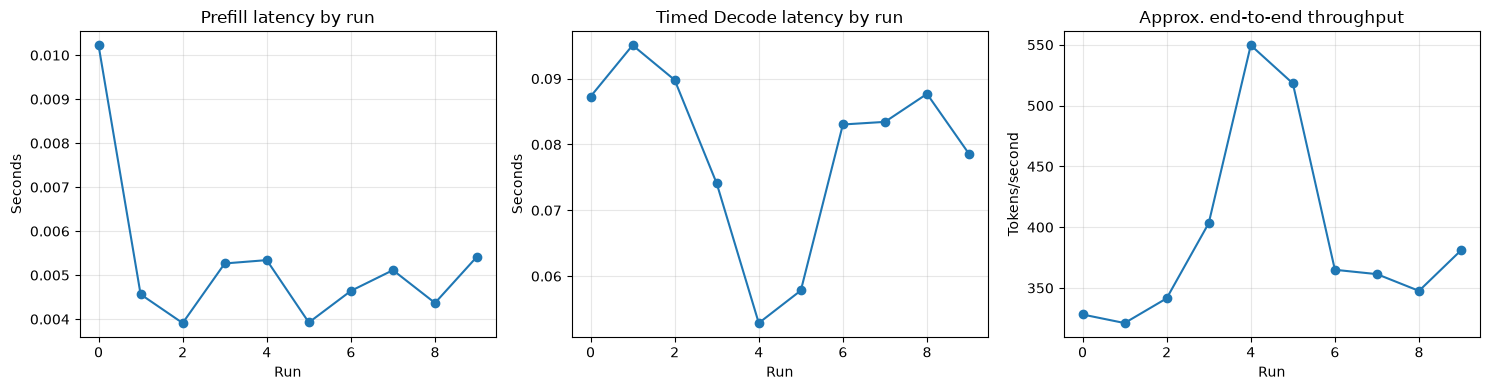

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
baseline_df["prefill_latency_s"].plot(kind="line", marker="o", ax=axes[0])
axes[0].set_title("Prefill latency by run")
axes[0].set_xlabel("Run")
axes[0].set_ylabel("Seconds")
axes[0].grid(True, alpha=0.3)

baseline_df["decode_latency_s"].plot(kind="line", marker="o", ax=axes[1])
axes[1].set_title("Timed Decode latency by run")
axes[1].set_xlabel("Run")
axes[1].set_ylabel("Seconds")
axes[1].grid(True, alpha=0.3)

baseline_df["end_to_end_tokens_per_s"].plot(kind="line", marker="o", ax=axes[2])
axes[2].set_title("Approx. end-to-end throughput")
axes[2].set_xlabel("Run")
axes[2].set_ylabel("Tokens/second")
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


## 7. Thí nghiệm A — ảnh hưởng của độ dài prompt

Chỉ thay đổi `prompt_tokens_requested`; giữ nguyên số token sinh, model, backend, số lần đo và warm-up. Danh sách mặc định vừa phải để phù hợp với model demo nhỏ; nếu đổi sang model lớn hơn, cần kiểm tra giới hạn context và bộ nhớ.


In [13]:
PROMPT_LENGTHS = [32, 64, 128, 256]
FIXED_NEW_TOKENS = 16

prompt_rows = []
for length in PROMPT_LENGTHS:
    print(f"\nPrompt experiment: prompt={length}, new_tokens={FIXED_NEW_TOKENS}")
    prompt_rows.extend(
        run_configuration(
            prompt_tokens=length,
            max_new_tokens=FIXED_NEW_TOKENS,
            experiment="prompt_length",
        )
    )

prompt_df = pd.DataFrame(prompt_rows)
prompt_summary = summarize_runs(
    prompt_df,
    ["experiment", "prompt_tokens_requested", "max_new_tokens_requested", "device"],
)
display_summary(prompt_summary)



Prompt experiment: prompt=32, new_tokens=16
  warm-up 1/2 (prompt=32, new=16)
  warm-up 2/2 (prompt=32, new=16)

Prompt experiment: prompt=64, new_tokens=16
  warm-up 1/2 (prompt=64, new=16)
  warm-up 2/2 (prompt=64, new=16)

Prompt experiment: prompt=128, new_tokens=16
  warm-up 1/2 (prompt=128, new=16)
  warm-up 2/2 (prompt=128, new=16)

Prompt experiment: prompt=256, new_tokens=16
  warm-up 1/2 (prompt=256, new=16)
  warm-up 2/2 (prompt=256, new=16)


,experiment,prompt_tokens_requested,max_new_tokens_requested,device,prefill_latency_s_count,prefill_latency_s_median,prefill_latency_s_mean,prefill_latency_s_std,prefill_latency_s_min,prefill_latency_s_max,...,prefill_latency_s_p90,decode_latency_s_p90,decode_step_latency_mean_s_p90,end_to_end_model_time_s_p90,decode_steps_per_s_p90,end_to_end_tokens_per_s_p90,process_rss_mb_p90,rss_delta_from_model_loaded_mb_p90,torch_allocated_mb_p90,torch_reserved_or_driver_mb_p90
0,prompt_length,32,16,mps,10,0.00358,0.00385,0.00064,0.00338,0.00540,...,0.00458,0.04212,0.00281,0.04595,536.49482,498.85747,522.3440,310.5630,0.401,1037.375
1,prompt_length,64,16,mps,10,0.00428,0.00476,0.00119,0.00377,0.00779,...,0.00560,0.06113,0.00408,0.06672,422.61221,402.79961,512.3280,300.5470,0.403,1037.375
2,prompt_length,128,16,mps,10,0.00620,0.00740,0.00311,0.00555,0.01583,...,0.00901,0.17403,0.01160,0.18304,415.11502,377.38455,519.9380,308.1570,0.406,1036.041
3,prompt_length,256,16,mps,10,0.00659,0.00653,0.00046,0.00565,0.00706,...,0.00692,0.03999,0.00267,0.04661,524.32050,454.32933,499.2531,287.4721,0.413,1043.953


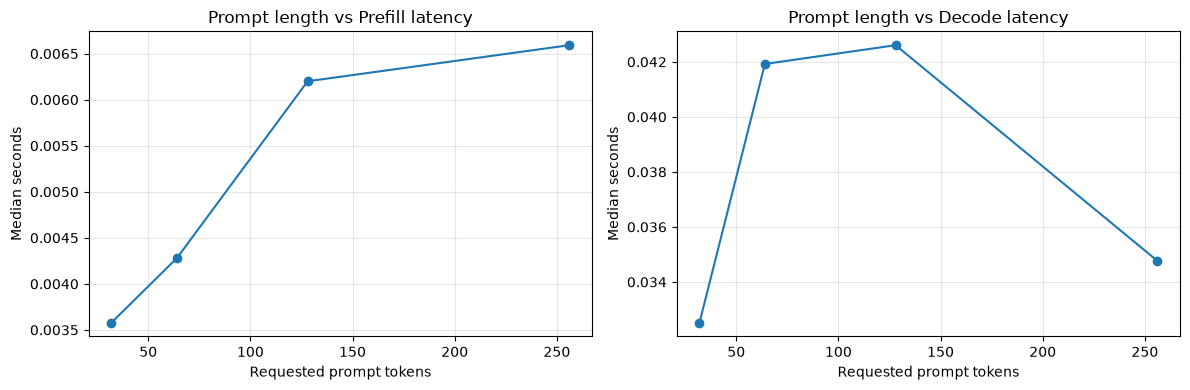

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for metric, label in [
    ("prefill_latency_s", "Prefill latency"),
    ("decode_latency_s", "Timed Decode latency"),
]:
    medians = prompt_df.groupby("prompt_tokens_requested")[metric].median()
    axes[0 if metric == "prefill_latency_s" else 1].plot(
        medians.index, medians.values, marker="o", label=label
    )

axes[0].set_title("Prompt length vs Prefill latency")
axes[0].set_xlabel("Requested prompt tokens")
axes[0].set_ylabel("Median seconds")
axes[0].grid(True, alpha=0.3)

axes[1].set_title("Prompt length vs Decode latency")
axes[1].set_xlabel("Requested prompt tokens")
axes[1].set_ylabel("Median seconds")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


## 8. Thí nghiệm B — ảnh hưởng của số token sinh

Chỉ thay đổi số token sinh; giữ prompt cố định. Lưu ý `decode_latency_s` chỉ cộng các bước decode sau token đầu tiên, còn token đầu tiên được lấy từ logits của Prefill. Vì vậy, `end_to_end_model_time_s` là tổng thời gian Prefill và các bước decode được bấm giờ, không phải thời gian tải model hay tokenization.


In [15]:
GENERATION_LENGTHS = [8, 16, 32, 64]
FIXED_PROMPT_TOKENS = 64

generation_rows = []
for length in GENERATION_LENGTHS:
    print(f"\nGeneration experiment: prompt={FIXED_PROMPT_TOKENS}, new_tokens={length}")
    generation_rows.extend(
        run_configuration(
            prompt_tokens=FIXED_PROMPT_TOKENS,
            max_new_tokens=length,
            experiment="generation_length",
        )
    )

generation_df = pd.DataFrame(generation_rows)
generation_summary = summarize_runs(
    generation_df,
    ["experiment", "prompt_tokens_requested", "max_new_tokens_requested", "device"],
)
display_summary(generation_summary)



Generation experiment: prompt=64, new_tokens=8
  warm-up 1/2 (prompt=64, new=8)
  warm-up 2/2 (prompt=64, new=8)

Generation experiment: prompt=64, new_tokens=16
  warm-up 1/2 (prompt=64, new=16)
  warm-up 2/2 (prompt=64, new=16)

Generation experiment: prompt=64, new_tokens=32
  warm-up 1/2 (prompt=64, new=32)
  warm-up 2/2 (prompt=64, new=32)

Generation experiment: prompt=64, new_tokens=64
  warm-up 1/2 (prompt=64, new=64)
  warm-up 2/2 (prompt=64, new=64)


,experiment,prompt_tokens_requested,max_new_tokens_requested,device,prefill_latency_s_count,prefill_latency_s_median,prefill_latency_s_mean,prefill_latency_s_std,prefill_latency_s_min,prefill_latency_s_max,...,prefill_latency_s_p90,decode_latency_s_p90,decode_step_latency_mean_s_p90,end_to_end_model_time_s_p90,decode_steps_per_s_p90,end_to_end_tokens_per_s_p90,process_rss_mb_p90,rss_delta_from_model_loaded_mb_p90,torch_allocated_mb_p90,torch_reserved_or_driver_mb_p90
0,generation_length,64,8,mps,10,0.00440,0.00444,0.00039,0.00395,0.00534,...,0.00473,0.01921,0.00274,0.02445,452.62071,406.65483,500.0160,288.2350,0.403,1045.953
1,generation_length,64,16,mps,10,0.00430,0.00466,0.00087,0.00378,0.00664,...,0.00541,0.03778,0.00252,0.04296,533.01062,499.40983,503.4097,291.6287,0.403,1045.953
2,generation_length,64,32,mps,10,0.00458,0.00618,0.00522,0.00386,0.02098,...,0.00680,0.07966,0.00257,0.08553,518.76340,502.57364,503.6689,291.8879,0.403,1045.953
3,generation_length,64,64,mps,10,0.00466,0.00478,0.00073,0.00401,0.00659,...,0.00524,0.15145,0.00240,0.15663,530.90278,519.51841,516.4426,304.6616,0.404,1038.453


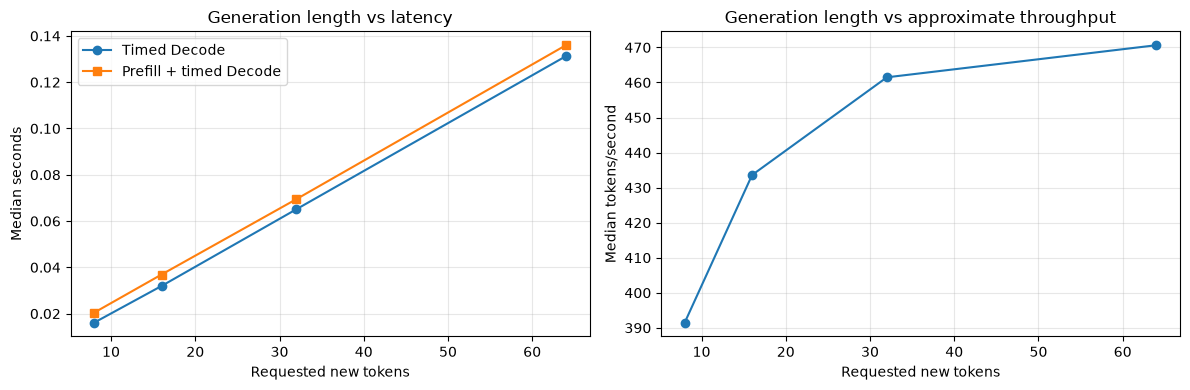

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

gen_grouped = generation_df.groupby("max_new_tokens_requested")
decode_median = gen_grouped["decode_latency_s"].median()
e2e_median = gen_grouped["end_to_end_model_time_s"].median()
throughput_median = gen_grouped["end_to_end_tokens_per_s"].median()

axes[0].plot(decode_median.index, decode_median.values, marker="o", label="Timed Decode")
axes[0].plot(e2e_median.index, e2e_median.values, marker="s", label="Prefill + timed Decode")
axes[0].set_title("Generation length vs latency")
axes[0].set_xlabel("Requested new tokens")
axes[0].set_ylabel("Median seconds")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(throughput_median.index, throughput_median.values, marker="o")
axes[1].set_title("Generation length vs approximate throughput")
axes[1].set_xlabel("Requested new tokens")
axes[1].set_ylabel("Median tokens/second")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


## 9. Tổng hợp bộ nhớ và kiểm tra độ ổn định

In [17]:
all_raw_df = pd.concat(
    [baseline_df, prompt_df, generation_df],
    ignore_index=True,
)

# Báo cáo độ dao động của các metric chính trên toàn bộ thí nghiệm.
stability_metrics = [
    "prefill_latency_s",
    "decode_latency_s",
    "end_to_end_model_time_s",
    "end_to_end_tokens_per_s",
    "process_rss_mb",
    "rss_delta_from_model_loaded_mb",
]
stability_rows = []
for (experiment, prompt_len, new_len), group in all_raw_df.groupby(
    ["experiment", "prompt_tokens_requested", "max_new_tokens_requested"],
    dropna=False,
):
    row = {
        "experiment": experiment,
        "prompt_tokens": prompt_len,
        "new_tokens": new_len,
        "n": len(group),
    }
    for metric in stability_metrics:
        values = group[metric].dropna()
        row[f"{metric}_median"] = values.median() if len(values) else None
        row[f"{metric}_std"] = values.std() if len(values) > 1 else 0.0
        row[f"{metric}_min"] = values.min() if len(values) else None
        row[f"{metric}_max"] = values.max() if len(values) else None
    stability_rows.append(row)

stability_df = pd.DataFrame(stability_rows)
display(stability_df.round(5))

print("Memory snapshot after model load:")
display(pd.Series(loaded_memory, name="MB").to_frame())


,experiment,prompt_tokens,new_tokens,n,prefill_latency_s_median,prefill_latency_s_std,prefill_latency_s_min,prefill_latency_s_max,decode_latency_s_median,decode_latency_s_std,...,end_to_end_tokens_per_s_min,end_to_end_tokens_per_s_max,process_rss_mb_median,process_rss_mb_std,process_rss_mb_min,process_rss_mb_max,rss_delta_from_model_loaded_mb_median,rss_delta_from_model_loaded_mb_std,rss_delta_from_model_loaded_mb_min,rss_delta_from_model_loaded_mb_max
0,baseline,64,32,10,0.00488,0.00183,0.00391,0.01023,0.08324,0.01379,...,321.14690,549.64091,493.3440,0.10171,493.062,493.406,281.5630,0.10171,281.281,281.625
1,generation_length,64,8,10,0.00440,0.00039,0.00395,0.00534,0.01611,0.00191,...,316.33002,409.89295,499.9610,0.02572,499.953,500.016,288.1800,0.02572,288.172,288.235
2,generation_length,64,16,10,0.00430,0.00087,0.00378,0.00664,0.03196,0.00469,...,323.67071,527.74727,500.9840,1.12938,500.969,503.578,289.2030,1.12938,289.188,291.797
3,generation_length,64,32,10,0.00458,0.00522,0.00386,0.02098,0.06510,0.01431,...,251.96461,506.78085,502.9840,4.71048,489.562,508.141,291.2030,4.71048,277.781,296.360
4,generation_length,64,64,10,0.00466,0.00073,0.00401,0.00659,0.13126,0.01445,...,389.26916,549.28274,516.3985,0.03024,516.391,516.484,304.6175,0.03024,304.610,304.703
5,prompt_length,32,16,10,0.00358,0.00064,0.00338,0.00540,0.03252,0.01260,...,217.98884,539.03741,522.3440,3.03326,512.844,522.344,310.5630,3.03326,301.063,310.563
6,prompt_length,64,16,10,0.00428,0.00119,0.00377,0.00779,0.04192,0.01206,...,209.05923,450.55248,504.4845,3.79199,502.969,512.328,292.7035,3.79199,291.188,300.547
7,prompt_length,128,16,10,0.00620,0.00311,0.00555,0.01583,0.04260,0.12126,...,36.36522,416.48139,519.8985,17.00316,471.922,519.938,308.1175,17.00316,260.141,308.157
8,prompt_length,256,16,10,0.00659,0.00046,0.00565,0.00706,0.03478,0.00516,...,319.08822,479.70077,497.8515,2.50392,493.109,499.281,286.0705,2.50392,281.328,287.500


Memory snapshot after model load:


,MB
process_rss_mb,211.781
torch_allocated_mb,0.398
torch_reserved_or_driver_mb,8.391


## 10. Tự động lưu dữ liệu và metadata

Notebook tạo:
- `raw_runs.csv`: mọi lượt đo riêng lẻ.
- `summary.csv`: median/mean/std/min/max/p90 theo cấu hình.
- `stability_summary.csv`: bảng tóm tắt độ dao động và bộ nhớ.
- `metadata.json`: model, thiết bị, cấu hình, phiên bản thư viện, thời điểm chạy và giải thích metric.

Các file được lưu trong `results/notebook_level1/`. Để so sánh nhiều phiên chạy, hãy lưu bản sao thư mục kết quả cùng với commit/version của notebook.


In [18]:
environment_metadata = {
    "timestamp_utc": datetime.now(timezone.utc).isoformat(),
    "model": MODEL,
    "device_requested": DEVICE_REQUESTED,
    "device_selected": DEVICE,
    "prompt_tokens_baseline": PROMPT_TOKENS,
    "new_tokens_baseline": NEW_TOKENS,
    "repeats": REPEATS,
    "warmup": WARMUP,
    "seed": SEED,
    "python_version": sys.version,
    "platform": platform.platform(),
    "machine": platform.machine(),
    "torch_version": torch.__version__,
    "transformers_version": transformers.__version__,
    "pandas_version": pd.__version__,
    "matplotlib_version": plt.matplotlib.__version__,
    "memory_after_model_load": loaded_memory,
    "metric_definitions": {
        "prefill_latency_s": "Wall-clock forward pass over the full prompt; excludes tokenization.",
        "decode_latency_s": "Sum of timed one-token decode forward passes after the first token from Prefill.",
        "decode_steps_per_s": "Number of timed decode calls divided by their summed latency; excludes the first generated token.",
        "end_to_end_model_time_s": "Prefill latency plus timed decode calls; excludes model loading, tokenization, saving, and plotting.",
        "end_to_end_tokens_per_s": "Requested generated token count divided by end_to_end_model_time_s; approximate model-time throughput.",
        "process_rss_mb": "Resident memory of the entire Python process, not model-only memory.",
        "torch_allocated_mb": "Backend-reported PyTorch allocated memory when the API is available.",
        "torch_reserved_or_driver_mb": "Backend-reported reserved/driver allocation when the API is available; semantics differ by backend.",
    },
    "notes": [
        "Model/tokenizer are loaded once and reused across all configurations.",
        "Warm-up runs are excluded from raw timing results.",
        "Latency measurements are wall-clock model-level measurements, not isolated kernel timings.",
        "Do not infer memory bandwidth, cache behavior, or a hardware bottleneck from latency alone.",
    ],
}

raw_path = OUTPUT_DIR / "raw_runs.csv"
summary_path = OUTPUT_DIR / "summary.csv"
stability_path = OUTPUT_DIR / "stability_summary.csv"
metadata_path = OUTPUT_DIR / "metadata.json"

all_raw_df.to_csv(raw_path, index=False)

all_summary_df = pd.concat(
    [baseline_summary, prompt_summary, generation_summary],
    ignore_index=True,
    sort=False,
)
all_summary_df.to_csv(summary_path, index=False)
stability_df.to_csv(stability_path, index=False)
metadata_path.write_text(
    json.dumps(environment_metadata, indent=2, ensure_ascii=False, default=str),
    encoding="utf-8",
)

print("Saved files:")
for path in [raw_path, summary_path, stability_path, metadata_path]:
    print(f"- {path.resolve()}")


Saved files:
- /Users/Huy/VSCode/DataProccessing/profiling_framework_mvp/notebooks/results/notebook_level1/raw_runs.csv
- /Users/Huy/VSCode/DataProccessing/profiling_framework_mvp/notebooks/results/notebook_level1/summary.csv
- /Users/Huy/VSCode/DataProccessing/profiling_framework_mvp/notebooks/results/notebook_level1/stability_summary.csv
- /Users/Huy/VSCode/DataProccessing/profiling_framework_mvp/notebooks/results/notebook_level1/metadata.json


## 11. Hướng dẫn diễn giải kết quả

1. **Kiểm tra độ ổn định trước:** so sánh median với std, min/max và p90. Nếu độ dao động lớn, hãy tăng số lần đo hoặc kiểm tra tải nền của máy.
2. **Prompt length:** nếu Prefill latency tăng theo prompt length, đây là quan sát phù hợp với khối lượng đầu vào tăng; riêng kết quả này chưa xác định được nguyên nhân ở mức kernel/phần cứng.
3. **Generation length:** tổng thời gian Decode thường tăng khi số token sinh tăng. Throughput có thể dao động do chi phí cố định, overhead backend và kích thước model; không nên diễn giải một xu hướng bất thường nếu phép đo chưa ổn định.
4. **Memory:** RSS bao gồm toàn bộ tiến trình Python. So sánh delta so với thời điểm model đã nạp để dễ đọc hơn, nhưng vẫn không coi đây là bộ nhớ riêng của model hoặc peak memory chính xác.
5. **Giới hạn model:** `sshleifer/tiny-gpt2` phù hợp kiểm tra pipeline, không đại diện cho hiệu năng của LLM lớn.
6. **Liên hệ nghiên cứu:** notebook này hoàn thiện phần *Observation* và thiết kế thí nghiệm. Để khẳng định nguyên nhân compute-bound/memory-bound, cache hoặc bottleneck phần cứng, cần bổ sung profiling ở mức operator/kernel và metric phù hợp trong một giai đoạn sau.

### Giới hạn và kiểm tra tính hợp lệ

- Chạy toàn bộ notebook từ đầu đến cuối để bảo đảm mọi bảng/biểu đồ được tạo từ cùng một phiên chạy.
- Không so sánh trực tiếp kết quả giữa các máy/backend khác nhau nếu chưa ghi rõ phần cứng, phiên bản thư viện và cấu hình.
- Nếu model không hỗ trợ `past_key_values` theo API hiện tại của Transformers, cần điều chỉnh phần decode cho đúng phiên bản thư viện đang cài.
- Nếu đổi sang model lớn, giảm prompt/generation lengths hoặc repeats trước để xác nhận notebook chạy ổn định.
